# 拉曼光谱塑料识别：六种方法与跨图泛化

《机器学习在物质科学中的应用》课程项目｜最终展示版 · 2026-11-16

**研究问题：用从未进入该模型训练的采集图，能否可靠识别塑料？复杂网络、增强和更多训练图能带来多大收益？**

10分钟主讲：依次阅读第1–6节；5分钟答问：查阅附录。Notebook保留绘图代码，HTML保留全部输出供离线展示。
成员姓名、学号和真实分工暂留待填，提交前必须补全。

## 1．先看结论（0:00–0:45）

- **15类固定六图测试，六方法已经补齐**：PCA64＋线性SVM准确率72.53%；ResNet平均宏F1为0.5913，SVM为0.5873，差距很小，不能宣称显著优势。
- **12类开发三折比较**：SVM宏F1为0.8742 ± 0.0721，CNN为0.8687 ± 0.0629；复杂模型没有稳定胜过经典基线。
- **12类旧六图补测**：36个既有模型分别推理相同5,425条谱，MLP宏F1最高，为0.6837 ± 0.0201。此处是已查看过的旧测试图上的后验补充评价，不是新外部盲测。

三套分数的类别、训练模型、评价总体和SD含义不同，不能合并成一个排行榜或据此直接宣称“提升”。

### 展示环境与证据入口

下面所有单元只读取本包中的CSV、JSON和已有图，不加载模型或大型NPZ，不进行训练与新测试。安装根目录requirements.txt后即可重跑展示；GPU仅用于完整重训/模型推理。

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Image
%matplotlib inline

ROOT = Path.cwd()
assert (ROOT / 'supplemental_study').is_dir(), '请在项目根目录启动Notebook'
STUDY = ROOT / 'extension_study'
SUPP = ROOT / 'supplemental_study'
SUMMARY = STUDY / 'results/summary'
def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding='utf-8'))
def read_csv(relative):
    return pd.read_csv(ROOT / relative)

available = {font.name for font in font_manager.fontManager.ttflist}
preferred = next((name for name in ['Microsoft YaHei', 'Noto Sans CJK SC', 'SimHei'] if name in available), 'DejaVu Sans')
plt.rcParams.update({'font.family': preferred, 'font.size': 11, 'figure.dpi': 120,
                     'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False})
ORDER = ['cosine_centroid', 'pca64_linear_svm', 'random_forest', 'cnn', 'mlp', 'resnet']
NAMES = ['余弦类中心', 'PCA64＋SVM', '随机森林', '1D-CNN', 'MLP', '1D-ResNet']
COLORS = ['#85919c', '#246b99', '#6b8764', '#bd7b38', '#8d5d96', '#ad5c63']
METHOD_NAME = dict(zip(ORDER, NAMES))
SHORT = {'acrylonitrile butadiene styrene': 'ABS', 'blank': 'blank', 'nylon': 'Nylon',
         'poly (methyl methacrylate)': 'PMMA', 'polycarbonate': 'PC', 'polyester': 'PEs',
         'polyethylene': 'PE', 'polyethylene terephthalate': 'PET', 'polyoxymethylene': 'POM',
         'polypropylene': 'PP', 'polystyrene': 'PS', 'polytetrafluoroethylene': 'PTFE',
         'polyurethane': 'PU', 'polyvinyl chloride': 'PVC', 'silicone': 'Sil'}
audit = read_json('data/processed/data_audit.json')
split = read_csv('data/processed/map_split.csv')
stage1 = read_csv('supplemental_study/results/stage1/summary/six_method_summary.csv').set_index('method').loc[ORDER]
cv_all = read_csv('extension_study/results/summary/condition_summary.csv')
cv_keys = ['baseline:cosine_centroid', 'baseline:pca64_linear_svm', 'baseline:random_forest_300',
           'architecture:cnn', 'architecture:mlp', 'architecture:resnet']
cv = cv_all.set_index('condition').loc[cv_keys]
hold = read_csv('supplemental_study/results/stage2_frozen_holdout/condition_summary.csv')
hold['method'] = hold.model.replace({'random_forest_300': 'random_forest'})
hold = hold.set_index('method').loc[ORDER]
assert len(stage1) == len(cv) == len(hold) == 6
print(f'展示复算环境：Python {platform.python_version()}；本Notebook不训练、不加载权重。')

展示复算环境：Python 3.12.14；本Notebook不训练、不加载权重。


## 2．数据与预处理（0:45–2:00）

数据为公开的RaMPI拉曼成像数据：34张采集map、33,119条像素光谱、14种塑料＋blank背景。数据许可CC BY 4.0，数据DOI：[10.5683/SP3/8UQQQN](https://doi.org/10.5683/SP3/8UQQQN)，对应论文DOI：[10.1038/s41597-026-07103-8](https://doi.org/10.1038/s41597-026-07103-8)。

**一个像素是一条谱，一张map含许多相关像素；33,119条谱不等于33,119个独立物理样品。** CSV原逐行标签显示塑料16,598条、blank16,521条；三张图与源元表/论文计数存在差异，本项目记录差异，保留原逐行标签，不擅自改标签来凑总数。

预处理顺序：波数轴升序 → 各图共同波数区间710.1758–1827 cm⁻¹ → 线性插值到1024点 → Savitzky–Golay平滑（窗口11、3阶）→ 两端各5点均值定义的线性基线 → 逐谱SNV。SNV为每条谱减自身均值、除自身标准差，弱化整体偏移和尺度差异；不用测试标签拟合变换。共同轴由全部34图频轴元信息确定，属于使用无标签采集元信息。

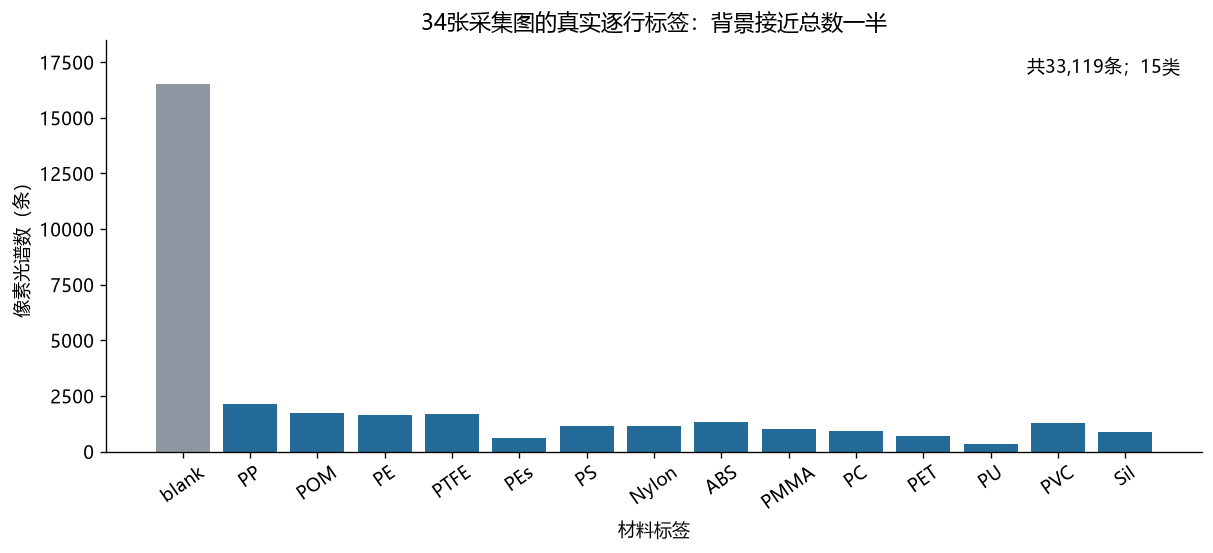

In [2]:
counts = pd.Series(audit['label_counts']).rename(index=SHORT)
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
bars = ax.bar(counts.index, counts.values, color=['#8e98a2' if x == 'blank' else '#246b99' for x in counts.index])
ax.set(ylabel='像素光谱数（条）', xlabel='材料标签', title='34张采集图的真实逐行标签：背景接近总数一半')
ax.tick_params(axis='x', rotation=35)
ax.set_ylim(0, 18500)
ax.text(0.98, 0.92, f"共{int(counts.sum()):,}条；{audit['class_count']}类", transform=ax.transAxes, ha='right')
plt.show()
assert int(counts.sum()) == 33119

### 波数轴与网格怎样理解？

波数轴是横坐标，单位cm⁻¹；各点的纵坐标是对应拉曼强度。网格是统一规定在哪些波数位置取值。下面只是“相同物理区间、原采样不同、插值后位置一致”的示意，不是实测光谱，也不额外生成模型输入。

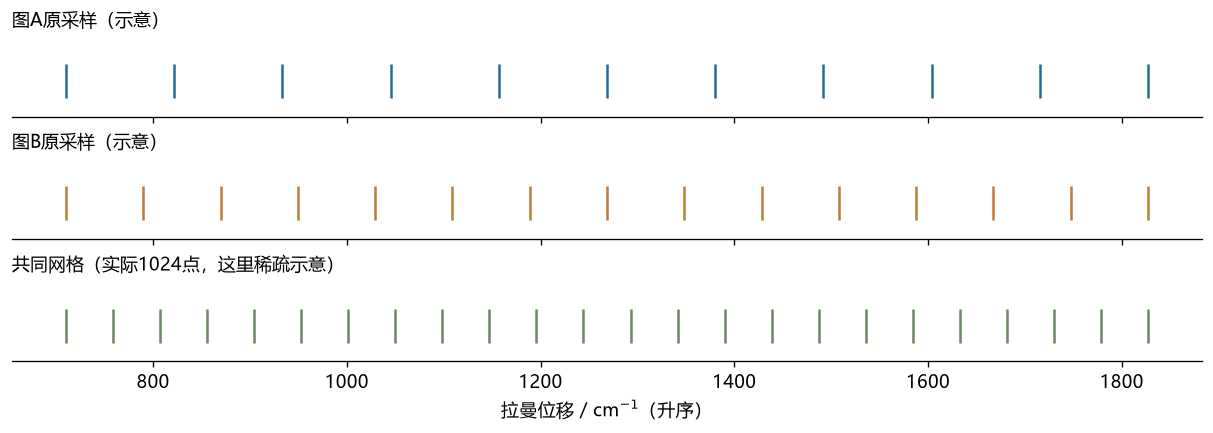

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 3.5), layout='constrained', sharex=True)
lo, hi = audit['common_axis_cm_inverse']
demo_axes = [np.linspace(lo, hi, 11), np.linspace(lo, hi, 15), np.linspace(lo, hi, 24)]
for ax, points, label, color in zip(axes, demo_axes, ['图A原采样（示意）', '图B原采样（示意）', '共同网格（实际1024点，这里稀疏示意）'], ['#246b99', '#bd7b38', '#6b8764']):
    ax.scatter(points, np.ones_like(points), marker='|', s=420, color=color)
    ax.set_ylim(0.6, 1.5); ax.set_yticks([]); ax.set_title(label, loc='left', fontsize=11)
    ax.spines[['left', 'top', 'right']].set_visible(False)
axes[-1].set_xlabel(r'拉曼位移 / cm$^{-1}$（升序）')
plt.show()

## 3．按采集图隔离，明确三种结果口径（2:00–3:30）

第一阶段固定划分为22张训练图、6张验证图、6张测试图，三组互不重叠。后来把训练＋验证的28张称为“开发图”；第二阶段仅用这28张做开发三折，原6张不参与该CV训练、早停和配置选择。不存在“丢了6张图”。

第二阶段要求保留类别在28张开发图中至少出现于3张图，才能让3个互斥外评价折都有该类别真值。PC仅2图，PU和Sil各1图，因此12类开发任务排除这3类；**不是看模型分数后任意挑12类**。标签范围变化也意味着15类与12类不能直接横比分数。

| 结果 | 类别与评价谱数 | 模型怎样得到 | ±代表什么 |
|---|---|---|---|
| 第一阶段固定六图 | 15类、6,399条 | 固定22/6训练/验证；六方法，神经42/43/44 | 同一测试集上3训练种子SD；传统单次不报SD |
| 第二阶段开发CV | 12类、25,541条、28图 | 3外折；每折另留5图内验证，训练13或14图 | 神经折内先平均3种子，再算3评价折的样本SD |
| 第二阶段旧六图补测 | 12类、5,425条 | 36个冻结CV模型分别推理；不重训、不集成 | 折内先平均3种子，再算3组既有拟合差异SD |

**关键边界：** 补齐第一阶段方法与第二阶段旧六图补测均发生于旧六图分数已经查看之后。追加计划在各自计算前冻结，但这不消除历史已查看事实；追加结果单列为后验补充证据。

In [4]:
roles = read_csv('extension_study/protocol/role_counts.csv')
role_table = roles.pivot(index='fold_id', columns='role', values='maps').rename(columns={
    'inner_train':'内训练图', 'inner_val':'内验证图', 'outer_eval':'外评价图'})
role_table['合计（原28开发图）'] = role_table.sum(axis=1)
display(role_table)
assert (role_table['合计（原28开发图）'] == 28).all()
assert split.map_id.is_unique and len(split) == 34
display(split.groupby('split').agg(图数=('map_id','size')))

role,内训练图,内验证图,外评价图,合计（原28开发图）
fold_id,,,,
1,13,5,10,28
2,14,5,9,28
3,14,5,9,28


,图数
split,
test,6
train,22
validation,6


### 六种方法分别做什么？

| 方法 | 核心思路 | 本项目输入/结构 |
|---|---|---|
| 余弦类中心 | 与各类训练均值谱比较方向相似程度 | 匹配基线 |
| PCA64＋线性SVM | PCA将1024维压成64个综合特征；SVM学习线性分类边界 | PCA仅在训练数据拟合 |
| 随机森林 | 300棵决策树综合投票 | 可学习非线性特征关系 |
| 1D-CNN | 卷积核沿波数移动，学习局部峰形组合 | 一维光谱卷积 |
| MLP | 全连接层学习各波数特征的组合 | 不显式共享局部卷积核 |
| 1D-ResNet | CNN基础上加入残差捷径，让卷积块学习对输入的修正 | 输出约为F(x)＋x；不代表更深就更好 |

**训练种子**是伪随机数发生器的起点，影响参数初始化、批次打乱和随机增强；42/43/44或101/202/303只是可复现的不同编号，不代表温度、轮数或特殊物理含义。

**增强**在训练时对谱施加小幅随机扰动：强度乘0.9–1.1、加入标准差0.02的高斯噪声、同批次最多平移2个网格点并复制边缘，扩展模型见到的输入变化；验证/评价不执行训练增强。精确定义见冻结代码与计划。“增强训练”与“换训练种子”是两个不同操作。

**准确率**为全部谱中预测正确的比例；**每类F1**兼顾精确率与召回率，F1＝2×精确率×召回率÷（精确率＋召回率）；**宏F1**对各有真值支持类的F1等权平均，避免blank像素多就掩盖少数塑料类。图等权宏F1先让各图总权重一致再算混淆矩阵，不是各图宏F1直接平均。

## 4．三组结果：先看同口径比较（3:30–6:45）

### 4.1 第一阶段：15类固定六图，六种方法已补齐

新增RF单次、MLP和ResNet各3训练种子，共7次真实拟合；历史CNN、SVM与余弦结果保留原值。主表神经方法每种3次，传统每种1次，共12条；含无增强CNN单次诊断的完整运行明细为13条，不能把它混入增强CNN均值。

误差棒仅神经方法显示3训练种子样本SD，传统单次的误差棒缺失表示未估计；不是零方差或置信区间。准确率显示百分比，F1在0–1之间。

,方法,像素准确率 %,宏F1,图等权宏F1
0,余弦类中心,64.87（单次）,0.4471（单次）,0.4942（单次）
1,PCA64＋SVM,72.53（单次）,0.5873（单次）,0.6216（单次）
2,随机森林,68.92（单次）,0.5632（单次）,0.5894（单次）
3,1D-CNN,70.50 ± 0.58,0.5725 ± 0.0181,0.6074 ± 0.0084
4,MLP,71.30 ± 1.22,0.5866 ± 0.0080,0.6169 ± 0.0087
5,1D-ResNet,71.35 ± 0.87,0.5913 ± 0.0079,0.6185 ± 0.0053


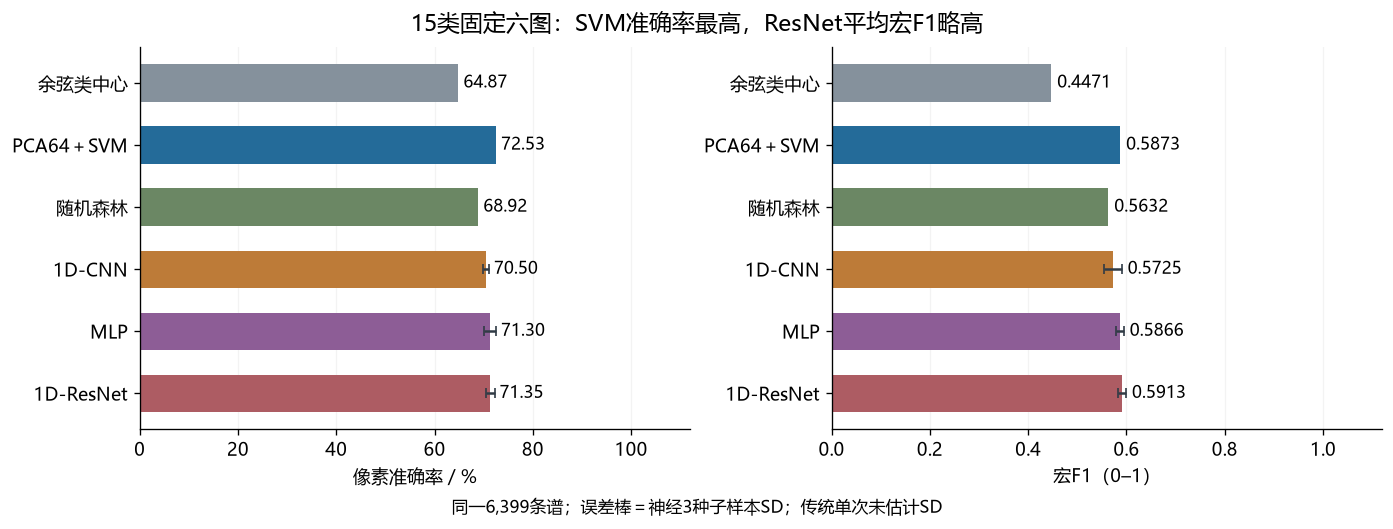

In [5]:
def metric_table(frame, sd_suffix, count_column=None):
    rows = []
    for method, name in zip(ORDER, NAMES):
        row = frame.loc[method]
        def fmt(metric, percent=False):
            scale = 100 if percent else 1
            digits = 2 if percent else 4
            mean, sd = row[metric+'_mean']*scale, row.get(metric+'_'+sd_suffix, np.nan)*scale
            return f'{mean:.{digits}f}' + (f' ± {sd:.{digits}f}' if pd.notna(sd) else '（单次）')
        rows.append({'方法':name, '像素准确率 %':fmt('accuracy', True),
                     '宏F1':fmt('macro_f1_present'), '图等权宏F1':fmt('map_equal_weight_macro_f1')})
    return pd.DataFrame(rows)

def plot_metrics(frame, sd_suffix, title, note):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout='constrained')
    positions = np.arange(6)
    for ax, metric, label, scale, digits in zip(axes, ['accuracy', 'macro_f1_present'],
                   ['像素准确率 / %', '宏F1（0–1）'], [100, 1], [2, 4]):
        values = frame[metric+'_mean'].to_numpy()*scale
        deviations = frame[metric+'_'+sd_suffix].to_numpy()*scale
        ax.barh(positions, values, color=COLORS, height=0.6)
        valid = np.isfinite(deviations)
        ax.errorbar(values[valid], positions[valid], xerr=deviations[valid], fmt='none', color='#303b45', capsize=3)
        ax.set_yticks(positions, NAMES); ax.invert_yaxis()
        ax.set_xlim(0, 112 if scale == 100 else 1.12)
        ax.set_xlabel(label); ax.grid(axis='x', alpha=0.15); ax.set_axisbelow(True)
        for pos, value, sd in zip(positions, values, deviations):
            x = value + (sd if np.isfinite(sd) else 0) + (1.0 if scale == 100 else .012)
            ax.text(x, pos, f'{value:.{digits}f}', va='center', fontsize=10)
    fig.suptitle(title, fontsize=14)
    fig.supxlabel(note, fontsize=10)
    plt.show()

display(metric_table(stage1, 'seed_sd'))
plot_metrics(stage1, 'seed_sd', '15类固定六图：SVM准确率最高，ResNet平均宏F1略高',
             '同一6,399条谱；误差棒＝神经3种子样本SD；传统单次未估计SD')

ResNet宏F1为0.5913 ± 0.0079，SVM为0.5873；小差距与后验追加设计不足以证明显著或普遍优势。历史神经训练使用RTX3090，新增拟合使用本机RTX3050 Ti，不能跨设备直接比较训练速度。

### 4.2 第二阶段：12类、28开发图的三折比较

本表与原始开发研究结果保持一致。神经每架构为3折×3种子101/202/303；传统每方法每折1次。原开发研究连同消融和学习曲线完成75次神经拟合与9组传统基线，不只本表六行。先在每折平均种子，再汇总3折；3折不是3批独立物理样品。外评价图未用于早停或重新挑参数。

,方法,像素准确率 %,宏F1,图等权宏F1
0,余弦类中心,79.90 ± 2.51,0.6746 ± 0.0832,0.6690 ± 0.1091
1,PCA64＋SVM,93.03 ± 3.68,0.8742 ± 0.0721,0.8635 ± 0.0802
2,随机森林,89.85 ± 6.14,0.8310 ± 0.1041,0.8234 ± 0.1058
3,1D-CNN,92.30 ± 3.47,0.8687 ± 0.0629,0.8560 ± 0.0627
4,MLP,91.48 ± 4.02,0.8490 ± 0.0813,0.8375 ± 0.0898
5,1D-ResNet,91.29 ± 4.09,0.8560 ± 0.0644,0.8482 ± 0.0603


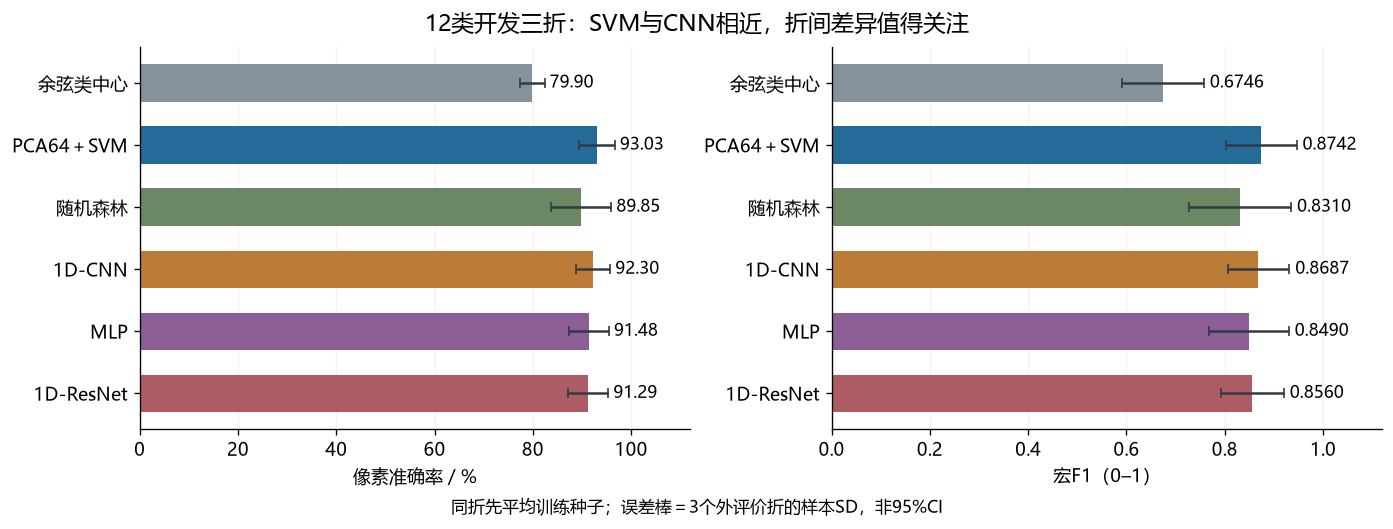

In [6]:
cv_display = cv.copy()
cv_display.index = ORDER
display(metric_table(cv_display, 'fold_sd'))
plot_metrics(cv_display, 'fold_sd', '12类开发三折：SVM与CNN相近，折间差异值得关注',
             '同折先平均训练种子；误差棒＝3个外评价折的样本SD，非95%CI')

SVM宏F1 0.8742 ± 0.0721，CNN 0.8687 ± 0.0629。开发图上的较高分数描述该受限12类总体，不可当作15类旧六图达到同样性能的证明。

### 4.3 第二阶段：36个冻结模型在原六图的12类补测

27个既有神经模型（3架构×3原外折×3种子）＋9个传统模型分别预测同一5,425条谱。没有全28图重新拟合、没有集成，也没有按补测分数选最好折或种子。这里的“折”标记权重来自哪一组开发训练，不是把六图又分成3个测试折。

,方法,像素准确率 %,宏F1,图等权宏F1
0,余弦类中心,68.70 ± 1.67,0.5096 ± 0.0298,0.5666 ± 0.0260
1,PCA64＋SVM,77.82 ± 0.66,0.6620 ± 0.0134,0.7127 ± 0.0077
2,随机森林,74.87 ± 1.79,0.6369 ± 0.0144,0.6738 ± 0.0039
3,1D-CNN,77.93 ± 1.44,0.6691 ± 0.0102,0.7070 ± 0.0071
4,MLP,79.21 ± 1.62,0.6837 ± 0.0201,0.7177 ± 0.0148
5,1D-ResNet,77.00 ± 1.81,0.6481 ± 0.0190,0.6841 ± 0.0150


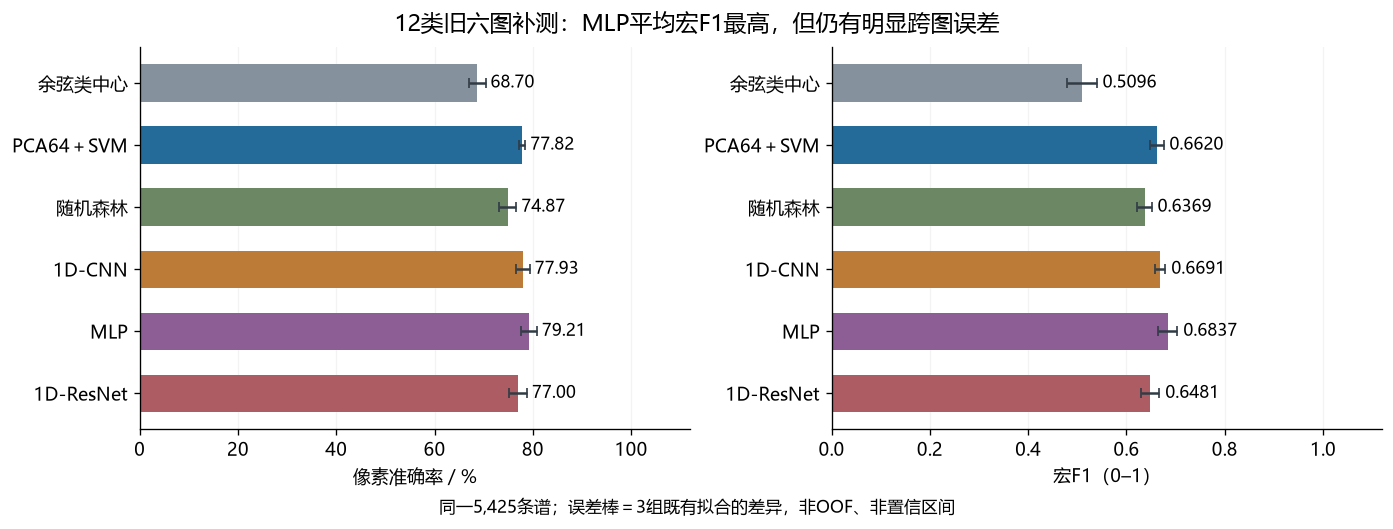

In [7]:
display(metric_table(hold, 'fold_sd'))
plot_metrics(hold, 'fold_sd', '12类旧六图补测：MLP平均宏F1最高，但仍有明显跨图误差',
             '同一5,425条谱；误差棒＝3组既有拟合的差异，非OOF、非置信区间')
assert int(hold.n_model_fits.sum()) == 36

MLP宏F1 0.6837 ± 0.0201。与开发CV相比排序和分数改变，说明开发图评价不足以覆盖这些旧图上的困难；不能直接把差异归因于某一种噪声或采集因素，更不能称作从未接触过的外部盲测。

### 补测中六张图还剩什么？

从原6,399条中，按已冻结12类规则排除PC578、PU78、Sil318，共974条，保留5,425条。PC_2和Silicone两图只剩1,077条blank，真正含塑料的仅4图；保留的每种塑料都只在1张补测图中有真值。因此须同时看总体与塑料像素表现。

,采集图,原谱数,纳入谱数,排除谱数,背景,塑料
0,Map_Env_PP_PTFE,2280,2280,0,854,1426
1,Map_Nylon_PEs_PS,750,750,0,242,508
2,Map_PC_2,1190,612,578,612,0
3,Map_PMMA_PET_PE_ABS,676,676,0,314,362
4,Map_PVC_PU_POM,720,642,78,468,174
5,Map_Silicone,783,465,318,465,0


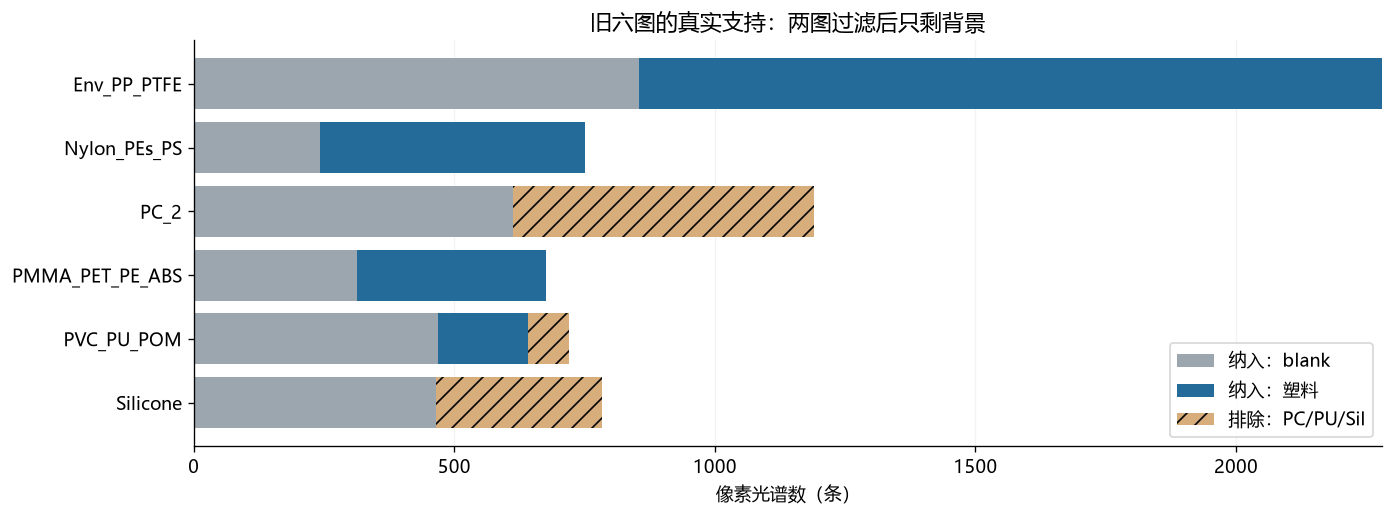

,评价总体,MLP像素准确率,MLP宏F1
1,全部6图纳入像素,0.7921,0.6837
7,仅背景的2图,0.9892,0.9946
13,仅4图中的塑料像素,0.5734,0.6674
19,有塑料支持的4图全部像素,0.7432,0.6843


In [8]:
support = read_csv('supplemental_study/results/stage2_frozen_holdout/map_support.csv')
assert support.original_pixels.sum() == 6399
assert support.eligible_pixels.sum() == 5425 and support.excluded_pixels.sum() == 974
display(support[['map_id','original_pixels','eligible_pixels','excluded_pixels','blank_pixels','plastic_pixels']].rename(columns={
    'map_id':'采集图', 'original_pixels':'原谱数', 'eligible_pixels':'纳入谱数', 'excluded_pixels':'排除谱数', 'blank_pixels':'背景', 'plastic_pixels':'塑料'}))
fig, ax = plt.subplots(figsize=(11.5, 4.2), layout='constrained')
short_maps = support.map_id.str.replace('Map_', '', regex=False)
ypos = np.arange(len(support))
ax.barh(ypos, support.blank_pixels, label='纳入：blank', color='#9ca6af')
ax.barh(ypos, support.plastic_pixels, left=support.blank_pixels, label='纳入：塑料', color='#246b99')
ax.barh(ypos, support.excluded_pixels, left=support.eligible_pixels, label='排除：PC/PU/Sil', color='#d7ad7c', hatch='//')
ax.set_yticks(ypos, short_maps); ax.invert_yaxis(); ax.set_xlabel('像素光谱数（条）')
ax.set_title('旧六图的真实支持：两图过滤后只剩背景')
ax.legend(loc='lower right'); ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
plt.show()
scopes = read_csv('supplemental_study/results/stage2_frozen_holdout/scope_summary.csv')
scope_display = scopes[scopes.model.eq('mlp')][['scope','accuracy_mean','macro_f1_present_mean']].copy()
scope_display['scope'] = scope_display.scope.replace({
    'all_eligible_pixels_6_maps':'全部6图纳入像素', 'blank_only_maps_2_maps':'仅背景的2图',
    'plastic_pixels_only_4_maps':'仅4图中的塑料像素', 'plastic_supported_maps_4_maps':'有塑料支持的4图全部像素'})
display(scope_display.rename(columns={'scope':'评价总体','accuracy_mean':'MLP像素准确率','macro_f1_present_mean':'MLP宏F1'}).round(4))

MLP全体像素准确率79.21%，仅塑料像素准确率57.34%，二者分母不同。只报告含大量背景的总准确率，会掩盖塑料识别仍然困难的事实。只看4张含塑料图也不能改变“各塑料只支持1图”的有限覆盖。

## 5．进一步分析：哪些设置带来收益？（6:45–8:45）

### 配对消融：增强、损失与预处理

“消融”指只关闭或替换一个组件，再与同折、同种子的参照相减。左图关闭增强/类别加权损失，参照为默认增强CNN，3折×3种子；右图预处理变体与无增强默认CNN同折seed101比较，仅3次配对。两组参照不同，不能混为同一个增强对照。

下面横坐标为“变体宏F1减参照宏F1”。正数表示变体更高，零表示相同。误差棒是先折内平均配对差后，3折差值的样本SD，不能作为显著性检验。

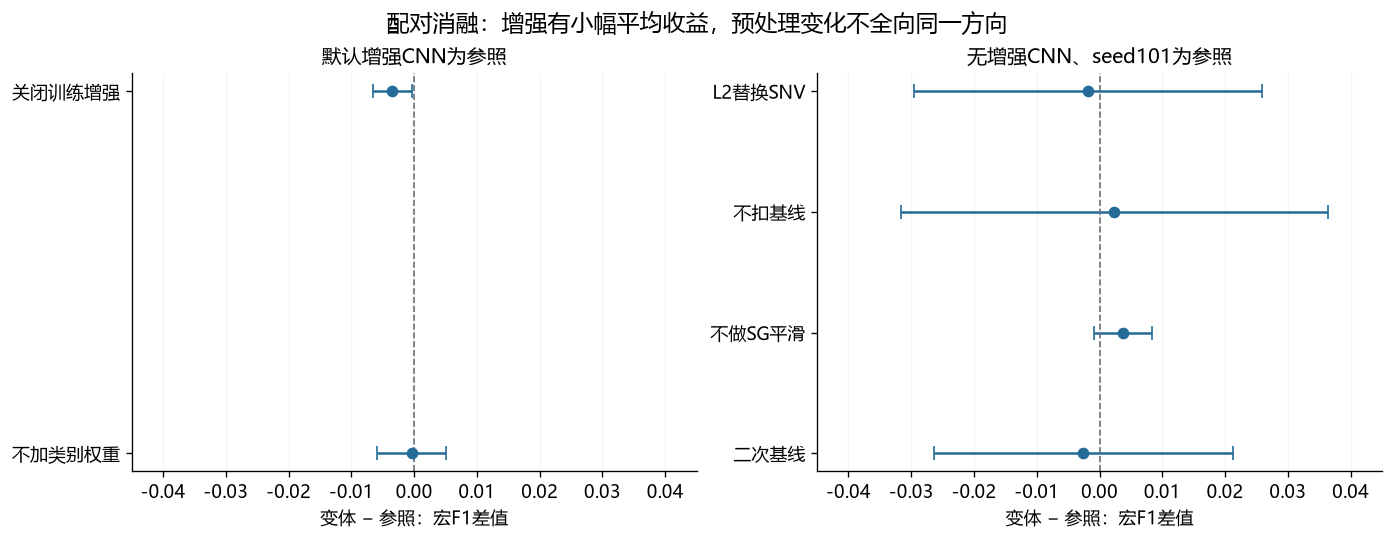

,配对宏F1差均值,3折差值SD
condition,,
noaug:cnn,-0.00351,0.00310
preprocessing:l2,-0.00185,0.02769
preprocessing:no_baseline,0.00231,0.03401
preprocessing:no_sg,0.00369,0.00462
preprocessing:quadratic,-0.00260,0.02379
unweighted:cnn,-0.00039,0.00546


In [9]:
paired = read_csv('extension_study/results/summary/paired_ablation_summary.csv').set_index('condition')
groups = [(['noaug:cnn','unweighted:cnn'], ['关闭训练增强','不加类别权重'], '默认增强CNN为参照'),
          (['preprocessing:l2','preprocessing:no_baseline','preprocessing:no_sg','preprocessing:quadratic'],
           ['L2替换SNV','不扣基线','不做SG平滑','二次基线'], '无增强CNN、seed101为参照')]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), layout='constrained')
for ax, (keys, labels, subtitle) in zip(axes, groups):
    part = paired.loc[keys]
    yy = np.arange(len(part))
    ax.errorbar(part.macro_f1_present_mean, yy, xerr=part.macro_f1_present_fold_sd,
                fmt='o', capsize=4, color='#246b99')
    ax.axvline(0, color='#66727d', linestyle='--', linewidth=1)
    ax.set_yticks(yy, labels); ax.invert_yaxis(); ax.set_xlim(-.045, .045)
    ax.set_title(subtitle, fontsize=12); ax.set_xlabel('变体 − 参照：宏F1差值')
    ax.grid(axis='x', alpha=.15)
fig.suptitle('配对消融：增强有小幅平均收益，预处理变化不全向同一方向', fontsize=14)
plt.show()
display(paired[['macro_f1_present_mean','macro_f1_present_fold_sd']].rename(columns={
    'macro_f1_present_mean':'配对宏F1差均值','macro_f1_present_fold_sd':'3折差值SD'}).round(5))

关闭增强的宏F1平均差为−0.00351，关闭类别权重为−0.00039；这些差异很小，不能概括成“增强一定有效”或“权重没有用”。预处理实验中不做SG平滑在这三折seed101平均略高，结论只限当前配对设计，不是通用最佳光谱处理建议。

### 学习曲线：增加的是训练图，不只是重复像素

每折从内训练图嵌套选取约60%、80%、100%，每层覆盖12类，内验证与外评价图固定；100%直接复用核心CNN。因向上取整，各折60%实际为约61.5%–64.3%，80%为约84.6%–85.7%。每个点先平均3种子，细线连接同一外折；粗线为3折均值。

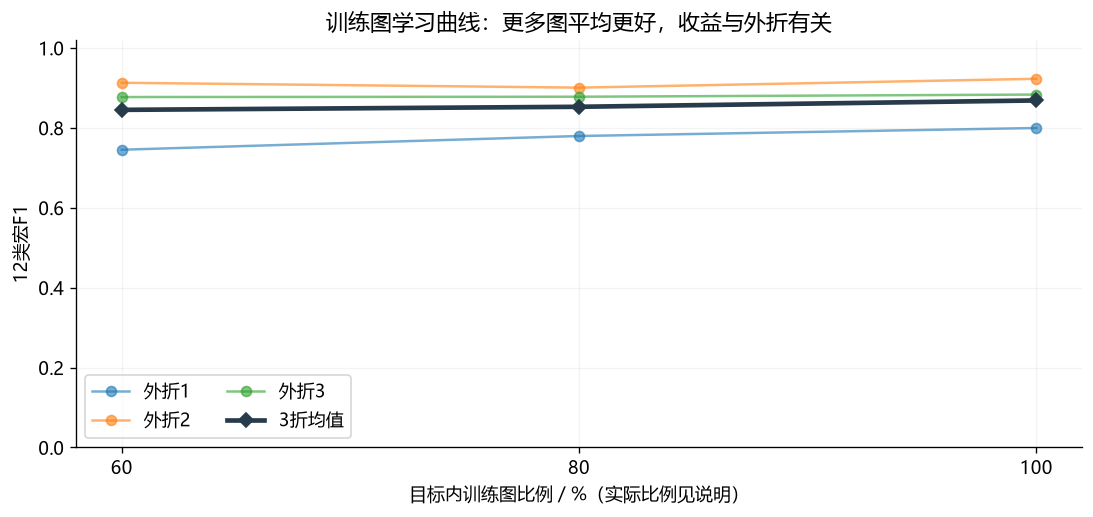

,fold_id,level,map_count,pixels,actual_map_fraction,macro_f1_present
0,1,maps100,13,10859,1.0000,0.7997
1,2,maps100,14,11410,1.0000,0.9229
2,3,maps100,14,13458,1.0000,0.8834
3,1,maps60,8,6992,0.6154,0.7453
4,2,maps60,9,7844,0.6429,0.9129
5,3,maps60,9,9961,0.6429,0.8772
6,1,maps80,11,8400,0.8462,0.7797
7,2,maps80,12,9282,0.8571,0.9008
8,3,maps80,12,11619,0.8571,0.8780


In [10]:
curve = read_csv('extension_study/results/summary/learning_curve_fold_means.csv')
level_order = ['maps60', 'maps80', 'maps100']
fig, ax = plt.subplots(figsize=(9, 4.2), layout='constrained')
for fold, group in curve.groupby('fold_id'):
    group = group.set_index('level').loc[level_order]
    ax.plot([60,80,100], group.macro_f1_present, marker='o', alpha=.6, label=f'外折{fold}')
means = curve.groupby('level').macro_f1_present.mean().loc[level_order]
ax.plot([60,80,100], means, marker='D', color='#273b4b', linewidth=2.8, label='3折均值')
ax.set(xticks=[60,80,100], xlabel='目标内训练图比例 / %（实际比例见说明）', ylabel='12类宏F1',
       ylim=(0,1.02), title='训练图学习曲线：更多图平均更好，收益与外折有关')
ax.legend(ncol=2); ax.grid(alpha=.15)
plt.show()
display(curve[['fold_id','level','map_count','pixels','actual_map_fraction','macro_f1_present']].round(4))

## 6．结论、边界与后续（8:45–10:00）

1. 实现了从公开数据审计、统一波数与预处理，到六种方法、按图评价、消融与误差诊断的完整流程。所有主表均有对应CSV、预测、配置和冻结审计。
2. 经典PCA＋SVM是有竞争力的基线；更深的ResNet未在所有口径稳定胜出。报告宏F1和图等权指标，能够发现总准确率隐藏的少数类问题。
3. 原12类开发CV与旧六图补测分数、排序不同，提示泛化依赖评价覆盖；单一来源数据、每类少数map、后验重复使用旧测试、无可靠独立标本/颗粒ID限制结论范围。
4. 下一步应预先锁定流程，收集未查看的新采集图、更多独立标本与颗粒ID，特别补充PC/PU/Sil；随后进行新的外部验证。当前数据不足以展示二维分割图，也不足以证明真实环境部署效果。

**成员待填：** 提交前填2–3位成员真实姓名、学号、实际贡献及展示/答问分工。AI辅助用于代码与文稿草拟、整理和检查；成员应实际复核并理解，不能虚构人工贡献。详细模板见docs目录成员说明。

主讲到此结束，下面材料供5分钟答问和复核。

## 附录A．扰动敏感性与置信度

### 模拟加噪：只是输入扰动诊断

在已经SNV处理后的输入加入标准差0/0.02/0.05/0.1/0.2的高斯噪声，不再SNV；同折同噪声水平共享扰动实现。模型不重新训练，不用这些结果挑最优条件。下面是原开发外评价结果，不是仪器信噪比标定或真实噪声外部验证。

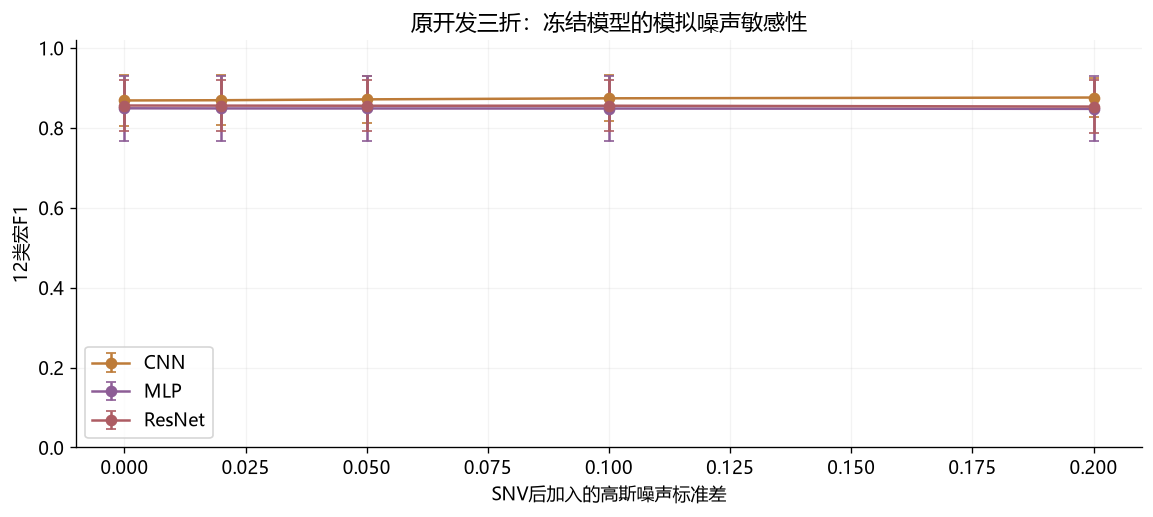

In [11]:
noise = read_csv('extension_study/results/summary/noise_summary.csv')
fig, ax = plt.subplots(figsize=(9.5, 4.2), layout='constrained')
for condition, name, color in [('architecture:cnn','CNN','#bd7b38'), ('architecture:mlp','MLP','#8d5d96'), ('architecture:resnet','ResNet','#ad5c63')]:
    part = noise[noise.condition.eq(condition)].sort_values('noise_std')
    ax.errorbar(part.noise_std, part.macro_f1_present_mean, yerr=part.macro_f1_present_fold_sd,
                marker='o', capsize=3, label=name, color=color)
ax.set(xlabel='SNV后加入的高斯噪声标准差', ylabel='12类宏F1', ylim=(0,1.02),
       title='原开发三折：冻结模型的模拟噪声敏感性')
ax.legend(); ax.grid(alpha=.15)
plt.show()

### ECE：信心与实际正确率是否一致？

ECE为按10个等宽置信度箱汇总的“平均信心与经验准确率差距”，越小表示在该分箱/总体下更接近。原开发CV保存的这份校准汇总仅覆盖神经模型；传统基线列为空，不画成零。第二阶段旧六图补测另保存RF概率，但不与原开发校准混用。余弦和LinearSVC未校准概率，不把判别得分当概率。未用外折拟合温度或阈值。

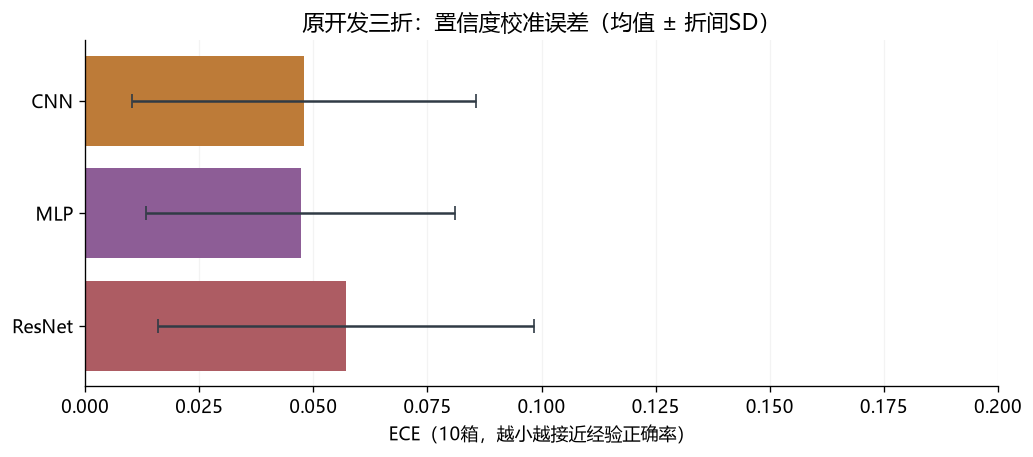

,ece_10_bins_mean,ece_10_bins_fold_sd
condition,,
architecture:cnn,0.0480,0.0376
architecture:mlp,0.0472,0.0338
architecture:resnet,0.0572,0.0412


In [12]:
cal = read_csv('extension_study/results/summary/calibration_summary.csv').set_index('condition')
cal_keys = ['architecture:cnn', 'architecture:mlp', 'architecture:resnet']
cal_part = cal.loc[cal_keys]
fig, ax = plt.subplots(figsize=(8.5, 3.7), layout='constrained')
ax.barh(['CNN','MLP','ResNet'], cal_part.ece_10_bins_mean, color=['#bd7b38','#8d5d96','#ad5c63'])
ax.errorbar(cal_part.ece_10_bins_mean, np.arange(3), xerr=cal_part.ece_10_bins_fold_sd, fmt='none', capsize=4, color='#303b45')
ax.invert_yaxis(); ax.set(xlabel='ECE（10箱，越小越接近经验正确率）', xlim=(0,.2),
                         title='原开发三折：置信度校准误差（均值 ± 折间SD）')
ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
plt.show()
display(cal_part[['ece_10_bins_mean','ece_10_bins_fold_sd']].round(4))

## 附录B．保存记录与独立复核

### 首阶段13条完整记录

六方法主表只使用增强CNN三种子；CNN_noaug是关闭训练增强的单次诊断。RF仅1次，无SD，不伪装成三次实验。新增七次拟合和原历史六次运行合计13条，但算法家族仍为6种。

In [13]:
runs = read_csv('supplemental_study/results/stage1/summary/combined_test_runs.csv')
print('完整记录行数：', len(runs), '；六方法主表运行数：', int(stage1.n_runs.sum()))
assert len(runs) == 13 and stage1.n_runs.sum() == 12
display(runs[['model','seed','training_condition','run_origin','accuracy','macro_f1_present']].round(4))

完整记录行数： 13 ；六方法主表运行数： 12


,model,seed,training_condition,run_origin,accuracy,macro_f1_present
0,cosine_centroid,NaN,not_applicable,historical_stage1,0.6487,0.4471
1,pca64_linear_svm,NaN,not_applicable,historical_stage1,0.7253,0.5873
2,cnn_aug_seed42,42.0,augmentation_weighted_CE,historical_stage1,0.6982,0.5530
3,cnn_aug_seed43,43.0,augmentation_weighted_CE,historical_stage1,0.7089,0.5757
4,cnn_aug_seed44,44.0,augmentation_weighted_CE,historical_stage1,0.7078,0.5887
5,cnn_noaug_seed42,42.0,no_augmentation_ablation,historical_stage1,0.7160,0.5733
6,random_forest_300_seed101,101.0,not_applicable,posthoc_supplement,0.6892,0.5632
7,mlp_aug_seed42,42.0,augmentation_weighted_CE,posthoc_supplement,0.7243,0.5945
8,mlp_aug_seed43,43.0,augmentation_weighted_CE,posthoc_supplement,0.7145,0.5869
9,mlp_aug_seed44,44.0,augmentation_weighted_CE,posthoc_supplement,0.7001,0.5785


### 展示中的一致性检查

这里核对保存CSV、JSON的计数、均值和来源口径，不执行模型前向。预测级独立审计另保存在supplemental_study/qa，覆盖原历史6条＋新增7条、36个补测模型与30份概率；其接近浮点精度的重算差异不意味着分类错误为零。

In [14]:
checks = {
    '34图唯一且划分互斥': split.map_id.is_unique and len(split) == 34,
    '原谱总数33119': audit['retained_spectra_count'] == 33119,
    '第一阶段六方法全部同6图6399谱': bool((stage1.maps.eq(6) & stage1.pixels.eq(6399)).all()),
    '开发CV每折覆盖28图': bool((role_table['合计（原28开发图）'] == 28).all()),
    '旧六图保留5425并排除974谱': int(support.eligible_pixels.sum()) == 5425 and int(support.excluded_pixels.sum()) == 974,
    '旧六图只有4图有塑料支持': int((support.plastic_pixels > 0).sum()) == 4,
    '补测36个既有模型': int(hold.n_model_fits.sum()) == 36,
}
# 独立复算汇总CSV均值；不写回任何科学结果文件。
main_runs = runs[~runs.training_condition.eq('no_augmentation_ablation')]
mean_check = main_runs.groupby('family')[['accuracy','macro_f1_present','map_equal_weight_macro_f1']].mean().loc[ORDER]
checks['首阶段六方法均值来自完整记录'] = bool(np.allclose(
    mean_check.to_numpy(), stage1[['accuracy_mean','macro_f1_present_mean','map_equal_weight_macro_f1_mean']].to_numpy(),
    rtol=0, atol=1e-14))
sd_check = main_runs.groupby('family')[['accuracy','macro_f1_present','map_equal_weight_macro_f1']].std(ddof=1).loc[['cnn','mlp','resnet']]
checks['神经种子SD从三次运行独立复算'] = bool(np.allclose(sd_check.to_numpy(),
    stage1.loc[['cnn','mlp','resnet'],['accuracy_seed_sd','macro_f1_present_seed_sd','map_equal_weight_macro_f1_seed_sd']].to_numpy(),
    rtol=0, atol=1e-14))
receipt = read_json('supplemental_study/qa/supplement_results_audit.json')
checks['独立预测审计passed'] = receipt['status'] == 'passed'
assert all(checks.values())
display(pd.DataFrame({'检查项':checks.keys(), '通过':checks.values()}))

,检查项,通过
0,34图唯一且划分互斥,True
1,原谱总数33119,True
2,第一阶段六方法全部同6图6399谱,True
3,开发CV每折覆盖28图,True
4,旧六图保留5425并排除974谱,True
5,旧六图只有4图有塑料支持,True
6,补测36个既有模型,True
7,首阶段六方法均值来自完整记录,True
8,神经种子SD从三次运行独立复算,True
9,独立预测审计passed,True


## 附录C．术语、来源与复现入口

| 术语 | 本项目中的含义 |
|---|---|
| map | 一张拉曼采集图的谱集合，不自动等于独立物理样品 |
| 开发图 | 原训练22图＋原验证6图，共28图 |
| 外评价折 | 开发CV中每次保留10/9/9图只作评价 |
| 内验证图 | 每折5图，用于早停；从未与内训练混合拟合 |
| epoch | 模型完整遍历一次训练数据；早停可能提前结束 |
| batch | 每次参数更新使用的一小批训练谱 |
| PCA | 主成分分析，以较少正交综合变量保留主要变化 |
| SVM | 支持向量机，学习有间隔的分类边界；本项目用线性SVM |
| CNN/ResNet | 卷积网络/带残差捷径的卷积网络 |
| SD | 标准差，本项目必须区分种子SD、评价折SD与同holdout拟合差异SD |
| OOF | 每个样本由不含它的训练折预测；开发CV互斥外折可汇集，旧六图36次重复预测不是OOF |
| 后验补充评价 | 旧测试表现已经查看后追加的分析，不能冒充首次盲测 |

**证据导航**

- 数据审计、真实标签计数与划分：data/processed/中的JSON与CSV；原文件ID/MD5与DOI获取方式见data/manifest.json。
- 第一阶段六方法表与13运行明细：supplemental_study/results/stage1/summary/。
- 原12类CV、消融、学习曲线、扰动及校准：extension_study/results/summary/；协议与类别资格见extension_study/protocol/。
- 旧六图补测、逐图支持与分层总体：supplemental_study/results/stage2_frozen_holdout/。
- 独立审计：supplemental_study/qa/supplement_results_audit.json；冻结计划和文件哈希是证据身份，不是未查看测试的保证。
- 21页工作详解与成员待填表、完整运行步骤见docs与README；无需另租服务器阅读结果或重跑本展示。

**引用与开源说明**

RaMPI原数据与论文按上述DOI及数据仓库作者信息引用，保留CC BY 4.0署名。方法实现依赖NumPy、pandas、SciPy、scikit-learn、Matplotlib、PyTorch、Jupyter及其原许可；使用现有架构思想重新实现1D模型，未声称原创发明CNN/ResNet。AI辅助生成和修改代码、图表与说明，最终使用者需核对结果并理解方法。开源许可、完整参考信息和实际成员分工见最终提交说明。

**复现层级**：轻量提交包足够重跑本Notebook（CSV/JSON/图）；完整复现包另含处理NPZ、全部原模型和新增权重/概率，可核查精确冻结模型并开展独立副本复跑。原始CSV按数据DOI与manifest重新获取，不因下载原CSV就自动恢复原训练权重。